<a href="https://colab.research.google.com/github/milena-seismo/DSB_capstone/blob/main/DSB_Capstone_Milena.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Data Collection and Dataset Description

The dataset used in this project is the 2024 earthquake catalogue provided by the **Sector for Seismology of the Institute of Hydrometeorology and Seismology (IHMS), Montenegro**.

The year 2024 was selected because of the **M 5.3 earthquake that occurred on 14 March 2024 near Čarađe, Montenegro**, followed by an intense aftershock sequence involving hundreds of seismic events.

The catalogue contains earthquake origin times, geographical coordinates, focal depths, magnitudes, and hypocentral location parameters.

The catalogue will serve as a reference dataset for comparing manually processed seismic events with automatically detected events using a pretrained EQTransformer deep learning model through the SeisBench Python library.


### Objectives of the Preliminary Analysis

- Examine the dataset structure and variables.
- Identify missing values, duplicates, and inconsistencies.
- Assess data quality and location uncertainties.
- Define the geographical study area.
- Analyze magnitude distribution and temporal and spatial seismic activity.

The aim is to prepare a reliable reference dataset and investigate whether machine learning can detect additional small earthquakes and improve seismic catalogue completeness.

In [1]:
# Import 2024 Montenegro eq catalogue into Panadas dataframe

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [4]:
import pandas as pd
kat = pd.read_csv('https://raw.githubusercontent.com/milena-seismo/DSB_capstone/refs/heads/main/2024_radna_kopija.csv')

In [5]:
kat.head()

,year,month,day,hour,minute,second,origin_time_sd_s,latitude_deg,latitude_sd_deg,longitude_deg,longitude_sd_deg,depth_km,depth_sd_km,magnitude_ML_or_Md,NST,GAP_deg
0,2024,1,2,0,25,20.57,0.22,42.6112,0.0034,19.8694,0.0048,9.0,1.2,1.0,28,81
1,2024,1,2,4,40,47.11,0.30,42.1433,0.0022,19.5921,0.0035,0.3,11.1,2.0,70,55
2,2024,1,4,11,53,54.97,0.26,42.9773,0.0058,18.6671,0.0069,0.0,11.1,1.5,18,167
3,2024,1,5,1,1,36.78,0.08,41.0184,0.0018,19.7590,0.0028,9.8,0.2,2.2,42,204
4,2024,1,5,15,42,51.21,0.25,42.6270,0.0066,18.8976,0.0127,23.0,1.5,1.5,14,138


In [6]:
kat.shape

(2293, 16)

In [8]:
kat.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2293 entries, 0 to 2292
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   year                2293 non-null   int64  
 1   month               2293 non-null   int64  
 2   day                 2293 non-null   int64  
 3   hour                2293 non-null   int64  
 4   minute              2293 non-null   int64  
 5   second              2293 non-null   float64
 6   origin_time_sd_s    2293 non-null   float64
 7   latitude_deg        2293 non-null   float64
 8   latitude_sd_deg     2293 non-null   float64
 9   longitude_deg       2293 non-null   float64
 10  longitude_sd_deg    2293 non-null   float64
 11  depth_km            2293 non-null   float64
 12  depth_sd_km         2293 non-null   float64
 13  magnitude_ML_or_Md  2293 non-null   float64
 14  NST                 2293 non-null   int64  
 15  GAP_deg             2293 non-null   int64  
dtypes: flo

In [9]:
kat.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
year,2293.0,2024.00,0.00,2024.00,2024.00,2024.00,2024.00,2024.00
month,2293.0,5.74,3.03,1.00,3.00,5.00,8.00,12.00
day,2293.0,15.41,8.23,1.00,8.00,15.00,22.00,31.00
hour,2293.0,11.16,7.38,0.00,4.00,11.00,18.00,23.00
minute,2293.0,29.24,17.19,0.00,15.00,29.00,44.00,59.00
second,2293.0,30.58,17.31,0.03,15.60,30.92,45.65,59.99
origin_time_sd_s,2293.0,0.26,0.43,0.00,0.12,0.18,0.28,11.24
latitude_deg,2293.0,42.20,1.53,33.23,41.92,42.87,43.00,48.14
latitude_sd_deg,2293.0,0.01,0.14,0.00,0.00,0.00,0.01,4.67
longitude_deg,2293.0,19.25,1.57,10.52,18.64,18.72,19.72,38.80


The initial statistical analysis shows that earthquake magnitudes range from 0.0 to 5.7, while focal depths range from 0 to 99.6 km.

The geographical coordinates indicate that the original catalogue includes seismic events from a wider region, not only Montenegro.

Some parameters show unusually high uncertainty values, which require further investigation.

Before continuing with the exploratory analysis, the dataset will be checked for potentially invalid values and filtered according to the selected geographical study area.

In [10]:
# Chack for eq magnitude=0
kat[kat['magnitude_ML_or_Md'] == 0]

,year,month,day,hour,minute,second,origin_time_sd_s,latitude_deg,latitude_sd_deg,longitude_deg,longitude_sd_deg,depth_km,depth_sd_km,magnitude_ML_or_Md,NST,GAP_deg
679,2024,3,23,21,28,55.03,0.10,42.9683,0.0039,18.6601,0.0063,12.1,0.9,0.0,14,228
923,2024,4,18,15,10,54.82,0.99,38.8000,0.9999,38.8000,0.9999,33.0,9.9,0.0,27,357
1807,2024,8,11,6,23,55.66,0.02,41.6738,0.0011,20.1776,0.0017,6.8,1.0,0.0,8,155
2053,2024,10,27,17,6,58.17,0.99,37.4000,0.9999,37.6000,0.9999,33.0,9.9,0.0,14,357
2249,2024,12,25,4,17,56.12,0.12,40.7669,0.0000,21.0131,0.0000,0.2,0.0,0.0,6,293


Data Quality Note: A focal depth of 33 km is a default value configured in the seismic processing system for teleseismic events. It may indicate that the earthquake depth was fixed rather than independently determined. Such records should be identified and treated with caution during depth analysis.

In [11]:
# Check for duplicate earthquake records
kat.duplicated().sum()

np.int64(1)

In [12]:
# Display duplicate earthquake records
kat[kat.duplicated(keep=False)]

,year,month,day,hour,minute,second,origin_time_sd_s,latitude_deg,latitude_sd_deg,longitude_deg,longitude_sd_deg,depth_km,depth_sd_km,magnitude_ML_or_Md,NST,GAP_deg
1026,2024,5,19,6,44,23.7,0.16,42.3946,0.0041,18.5442,0.0071,7.2,1.2,1.1,18,212
1170,2024,5,19,6,44,23.7,0.16,42.3946,0.0041,18.5442,0.0071,7.2,1.2,1.1,18,212


In [13]:
# Remove duplicate eq records
kat = kat.drop_duplicates()

In [14]:
kat.shape

(2292, 16)

In [15]:
# Count eq with the default depth of 33 km
(kat['depth_km'] == 33).sum()

np.int64(2)

Two earthquake records have a focal depth of 33 km, which is the default depth configured in the seismic processing system.

Both records also have a reported magnitude of 0.0 and unusually high location uncertainties.

These records will be reviewed during geographical filtering.

In [17]:
# Count earthquakes with a depth of 0 km
(kat['depth_km'] == 0).sum()

np.int64(80)

In [18]:
# Display earthquakes with a depth of 0 km
kat[kat['depth_km'] == 0].head(10)

,year,month,day,hour,minute,second,origin_time_sd_s,latitude_deg,latitude_sd_deg,longitude_deg,longitude_sd_deg,depth_km,depth_sd_km,magnitude_ML_or_Md,NST,GAP_deg
2,2024,1,4,11,53,54.97,0.26,42.9773,0.0058,18.6671,0.0069,0.0,11.1,1.5,18,167
29,2024,1,13,2,58,34.60,0.52,36.5053,0.7937,23.0539,1.4708,0.0,11.1,4.7,44,343
35,2024,1,14,13,0,49.21,0.22,42.3638,0.0036,19.4601,0.0042,0.0,11.1,1.5,24,76
44,2024,1,16,5,15,28.02,0.42,40.2889,0.0193,19.8181,0.0253,0.0,11.1,3.2,20,276
64,2024,1,25,0,50,4.77,0.20,42.3295,0.0018,19.9112,0.0025,0.0,11.1,2.0,50,54
71,2024,1,27,3,10,42.56,0.45,39.1042,0.0950,20.6997,0.1334,0.0,11.1,3.5,24,293
99,2024,2,2,13,20,20.74,0.19,43.4110,0.0029,19.0012,0.0036,0.0,11.1,2.0,40,160
135,2024,2,15,2,17,9.81,0.05,42.3066,0.0019,18.7537,0.0020,0.0,11.1,1.3,16,196
202,2024,3,1,10,57,57.75,0.18,43.3921,0.0029,19.0343,0.0041,0.0,11.1,1.7,32,155
203,2024,3,1,11,50,33.01,0.26,42.8331,0.0040,19.1260,0.0108,0.0,11.1,1.8,18,168


### Checking Zero Depth Values

A total of 80 earthquake records have a focal depth of 0 km.

These values are associated with poor seismic data processing and unreliable hypocentral depth determination.

The records will be retained at this stage but flagged for further quality assessment.

In [19]:
# Check depth uncertainties for earthquakes with zero depth
kat[kat['depth_km'] == 0]['depth_sd_km'].describe()

,depth_sd_km
count,8.000000e+01
mean,1.110000e+01
std,1.430051e-14
min,1.110000e+01
25%,1.110000e+01
50%,1.110000e+01
75%,1.110000e+01
max,1.110000e+01


In [20]:
# Check all records with a depth uncertainty of 11.1 km
kat[kat['depth_sd_km'] == 11.1].shape

(156, 16)

In [21]:
# Display earthquakes with non-zero depth and uncertainty of 11.1 km
kat[(kat['depth_sd_km'] == 11.1) & (kat['depth_km'] != 0)].head(10)

,year,month,day,hour,minute,second,origin_time_sd_s,latitude_deg,latitude_sd_deg,longitude_deg,longitude_sd_deg,depth_km,depth_sd_km,magnitude_ML_or_Md,NST,GAP_deg
1,2024,1,2,4,40,47.11,0.30,42.1433,0.0022,19.5921,0.0035,0.3,11.1,2.0,70,55
5,2024,1,5,15,52,36.41,0.61,38.7444,0.0890,20.9075,0.1680,7.3,11.1,3.8,18,224
8,2024,1,6,4,23,26.30,0.72,39.3887,0.0673,16.7713,0.0846,0.2,11.1,3.7,26,225
43,2024,1,16,4,8,27.92,0.75,37.5273,4.6675,21.6317,12.2910,9.0,11.1,4.2,18,348
45,2024,1,16,5,20,51.86,1.83,37.2682,0.5405,22.4205,0.5468,5.8,11.1,5.2,43,315
73,2024,1,27,5,19,19.54,1.20,37.9873,0.0595,27.1062,0.0873,0.1,11.1,5.5,20,126
95,2024,2,22,11,21,8.32,0.42,38.9439,0.1205,22.3471,0.1263,6.7,11.1,4.2,64,313
108,2024,2,8,5,32,9.94,0.70,41.1587,0.0067,20.2265,0.0121,0.3,11.1,3.9,65,101
109,2024,2,8,5,35,23.98,1.14,41.9326,0.0479,21.1218,0.0655,0.9,11.1,3.2,28,297
113,2024,2,9,12,6,53.92,2.61,43.3790,0.1635,13.6676,0.9117,13.0,11.1,4.0,19,231


### Depth Uncertainty Analysis

A total of 156 earthquake records have a depth uncertainty of exactly 11.1 km, including 80 events with a focal depth of 0 km.

The remaining records have different focal depths, magnitudes, and station geometries.

This suggests that 11.1 km may represent a default uncertainty value associated with unreliable depth determination.

These records will be retained but considered separately in the assessment of hypocentral location quality.

<Axes: >

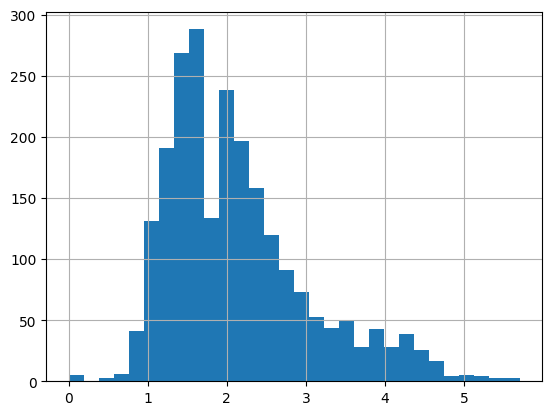

In [22]:
# Plot the distribution of earthquake magnitudes
kat['magnitude_ML_or_Md'].hist(bins=30)

<Axes: >

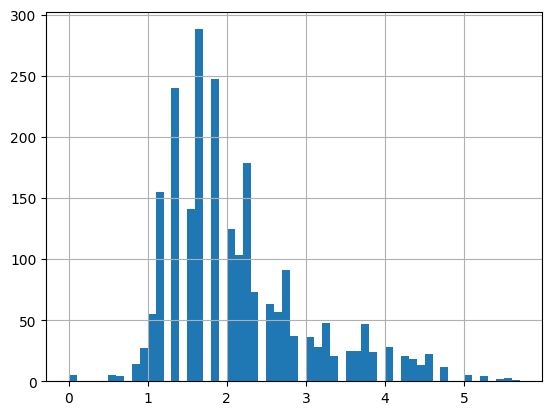

In [23]:
# Plot magnitude distribution using 0.1 magnitude intervals
kat['magnitude_ML_or_Md'].hist(bins=57)

In [24]:
# Count earthquakes for each magnitude
kat['magnitude_ML_or_Md'].value_counts().sort_index()

,count
magnitude_ML_or_Md,
0.0,5
0.5,3
0.6,2
0.7,4
0.8,14
0.9,27
1.0,55
1.1,76
1.2,79


### Magnitude Frequency Analysis

The frequency analysis shows that the most common magnitude is 1.6, with 166 recorded earthquakes.

Magnitudes between 0.5 and 4.8 are represented at every 0.1 magnitude increment.

The apparent gaps in the histogram are mainly related to the binning of discrete magnitude values.

The low number of small-magnitude events may indicate detection limitations, which will be investigated during the catalogue completeness analysis.

In [25]:
# Count eq by month
kat['month'].value_counts().sort_index()

,count
month,
1,95
2,101
3,533
4,295
5,214
6,198
7,212
8,158
9,143


### Monthly Earthquake Distribution

The highest number of earthquakes was recorded in March 2024, with 533 events, followed by April with 295 events.

The increased seismic activity in March is consistent with the occurrence of the Čarađe earthquake and its aftershock sequence.

However, the catalogue covers a wider geographical region, so further spatial filtering is required to isolate the aftershock sequence.

<Axes: xlabel='month'>

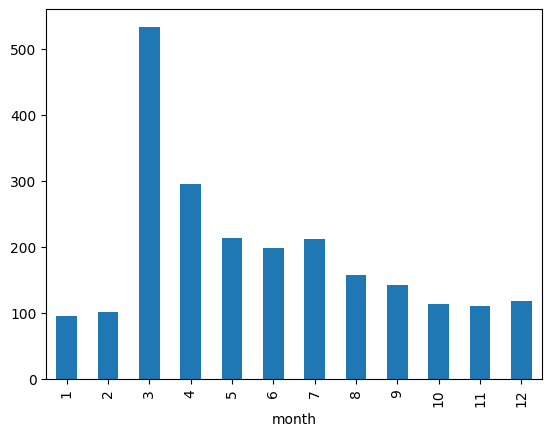

In [26]:
# Plot the monthly distribution of earthquakes
kat['month'].value_counts().sort_index().plot(kind='bar')

<Axes: xlabel='longitude_deg', ylabel='latitude_deg'>

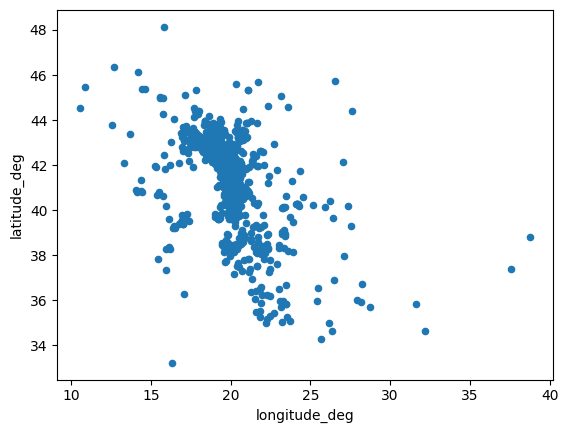

In [27]:
# Plot the spatial distribution of earthquake eq
kat.plot.scatter(x='longitude_deg', y='latitude_deg')

<Axes: xlabel='longitude_deg', ylabel='latitude_deg'>

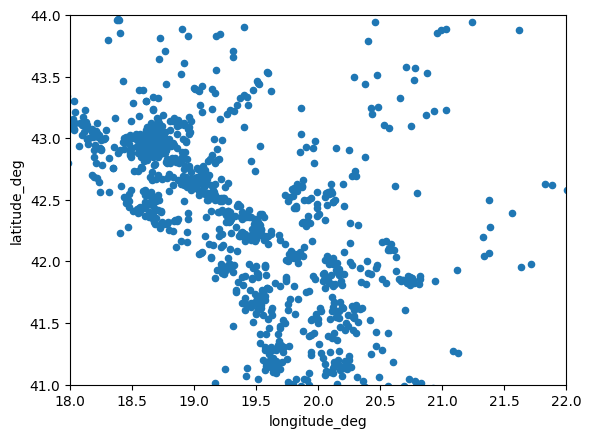

In [28]:
# Zoom in on Montenegro and the surrounding region
kat.plot.scatter(x='longitude_deg', y='latitude_deg',
                 xlim=(18, 22), ylim=(41, 44))

<Axes: xlabel='longitude_deg', ylabel='latitude_deg'>

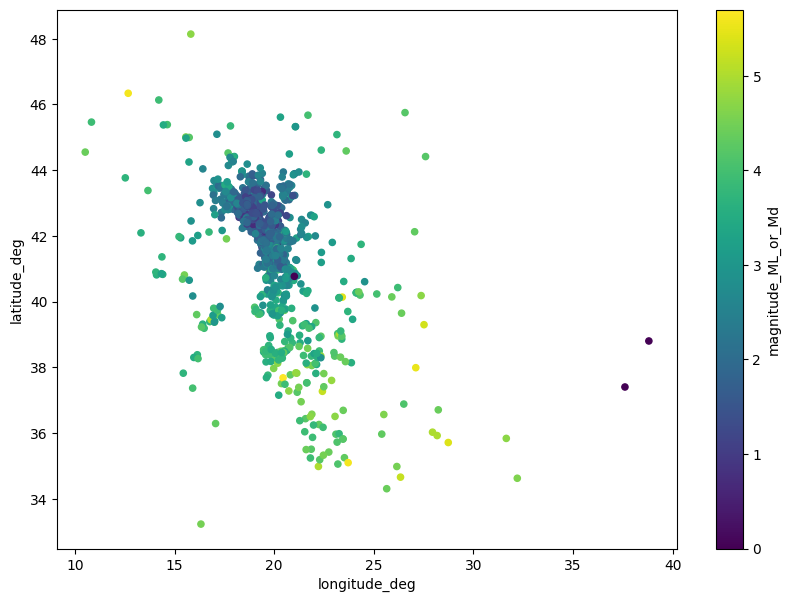

In [29]:
# Plot earthquake epicenters colored by magnitude
kat.plot.scatter(
    x='longitude_deg',
    y='latitude_deg',
    c='magnitude_ML_or_Md',
    cmap='viridis',
    figsize=(10, 7)
)

<Axes: xlabel='longitude_deg', ylabel='latitude_deg'>

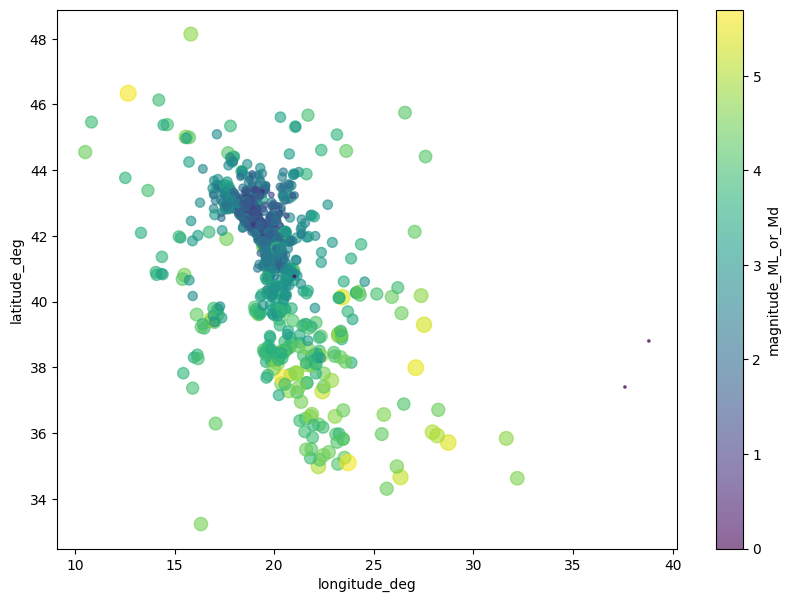

In [30]:
# Plot earthquake epicenters by magnitude
kat.plot.scatter(
    x='longitude_deg',
    y='latitude_deg',
    c='magnitude_ML_or_Md',
    s=(kat['magnitude_ML_or_Md'] + 1)**2 * 3,
    cmap='viridis',
    alpha=0.6,
    figsize=(10, 7)
)

In [31]:
# Display earthquakes with magnitude 5.0 or greater
kat[kat['magnitude_ML_or_Md'] >= 5][
    ['month', 'day', 'latitude_deg', 'longitude_deg', 'magnitude_ML_or_Md']
]

,month,day,latitude_deg,longitude_deg,magnitude_ML_or_Md
23,1,12,34.9816,22.2208,5.0
45,1,16,37.2682,22.4205,5.2
73,1,27,37.9873,27.1062,5.5
414,3,14,42.9761,18.6537,5.3
714,3,27,46.3383,12.6761,5.6
718,3,29,37.6784,20.4459,5.7
958,4,22,35.7103,28.7352,5.4
1150,5,15,34.6567,26.3399,5.2
1297,6,11,39.0144,23.2974,5.0
1306,6,12,36.0250,27.9455,5.0


### Spatial Distribution of Earthquakes

The plot shows the spatial distribution of earthquakes across a wider geographical region.

The catalogue includes several stronger earthquakes with epicenters outside Montenegro. These events will not be considered in this project, as the analysis will focus on seismic activity in Montenegro and the selected study area.
A more detailed spatial analysis will be conducted within the Čarađe epicentral area. The exact geographical boundaries will be defined during the next stage of data preparation.

<Axes: xlabel='longitude_deg', ylabel='latitude_deg'>

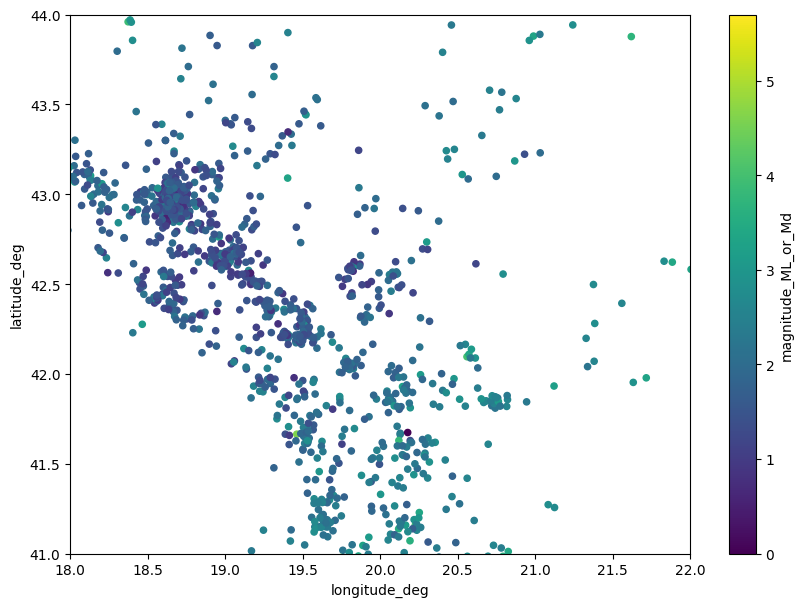

In [32]:
# Plot earthquakes in Montenegro and the surrounding region
kat.plot.scatter(
    x='longitude_deg',
    y='latitude_deg',
    c='magnitude_ML_or_Md',
    cmap='viridis',
    xlim=(18, 22),
    ylim=(41, 44),
    figsize=(10, 7)
)

Text(19.0, 43.3, 'Čarađe M 5.3')

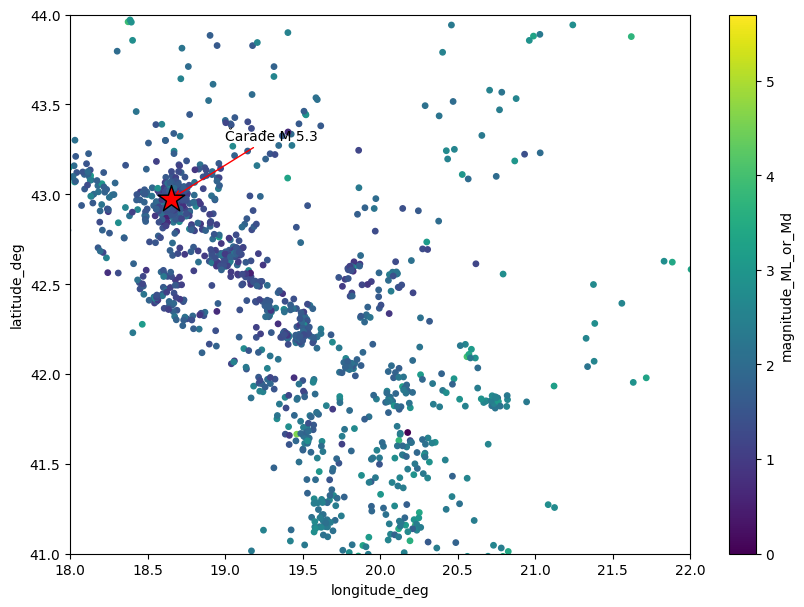

In [34]:
# Plot earthquake epicenters colored by magnitude
ax = kat.plot.scatter(
    x='longitude_deg',
    y='latitude_deg',
    c='magnitude_ML_or_Md',
    cmap='viridis',
    s=15,
    xlim=(18, 22),
    ylim=(41, 44),
    figsize=(10, 7)
)

# Highlight the main Čarađe earthquake (M 5.3)
ax.scatter(18.6537, 42.9761, s=400, c='red',
           marker='*', edgecolors='black', zorder=10)

ax.annotate('Čarađe M 5.3',
            xy=(18.6537, 42.9761),
            xytext=(19.0, 43.3),
            arrowprops=dict(arrowstyle='->', color='red'))

In [35]:
# Select earthquakes in Montenegro and the surrounding region
cg = kat[
    (kat['longitude_deg'] >= 18) &
    (kat['longitude_deg'] <= 22) &
    (kat['latitude_deg'] >= 41) &
    (kat['latitude_deg'] <= 44)
]

cg.shape

(1824, 16)

### Geographical Filtering

The original catalogue contains 2,292 earthquake records.

After applying a geographical filter (18°–22° E and 41°–44° N), 1,824 earthquakes remain within the selected region.

A total of 468 events fall outside this area.

The original dataset remains unchanged. The filtered dataset will be used for further exploratory analysis.

<Axes: >

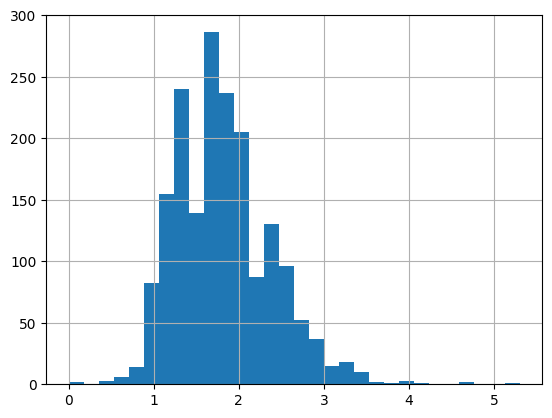

In [36]:
# Plot magnitude distribution for the selected region
cg['magnitude_ML_or_Md'].hist(bins=30)

### Magnitude Distribution in the Selected Region

The magnitude distribution shows that most recorded earthquakes have magnitudes between 1.0 and 2.5.

The frequency of earthquakes generally decreases towards higher magnitudes.

This distribution provides a basis for further investigation of seismic catalogue completeness, particularly for smaller events.

In [37]:
# Count earthquakes by month in the selected region
cg['month'].value_counts().sort_index()

,count
month,
1,55
2,66
3,476
4,269
5,176
6,160
7,169
8,95
9,112


### Monthly Seismic Activity in the Selected Region

The highest seismic activity was recorded in March 2024, with 476 earthquakes, followed by April with 269 events.

The significant increase in March is consistent with the Čarađe earthquake and its aftershock activity.

Further spatial and temporal analysis is required to distinguish the Čarađe aftershock sequence from other earthquakes in the region.

<Axes: xlabel='month'>

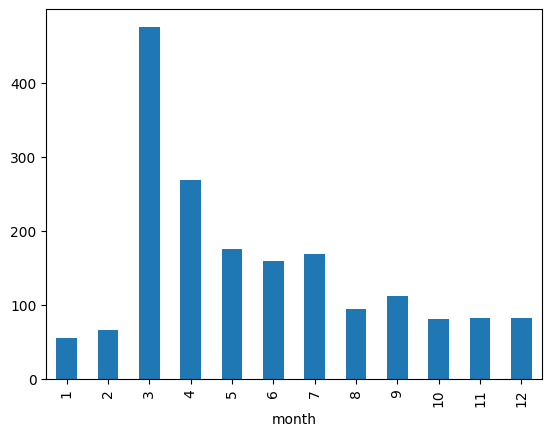

In [38]:
# Plot monthly earthquake distribution in the selected region
cg['month'].value_counts().sort_index().plot(kind='bar')

In [40]:
# Count eq in magnitude intervals
pd.cut(
    cg['magnitude_ML_or_Md'],
    bins=[0, 1, 2, 3, 4, 5, 6],
    right=False
).value_counts().sort_index()

,count
magnitude_ML_or_Md,
"[0, 1)",52
"[1, 2)",1112
"[2, 3)",589
"[3, 4)",66
"[4, 5)",4
"[5, 6)",1


### Preliminary EDA Conclusions

The original 2024 seismic catalogue contained 2,293 earthquake records. After removing one duplicate, 2,292 unique events remained.

Geographical filtering reduced the dataset to 1,824 earthquakes within Montenegro and the surrounding region.

The magnitude analysis showed that 1,701 earthquakes (93.3%) had magnitudes between 1.0 and 3.0, while only 52 events (2.9%) had magnitudes below 1.0.

The highest seismic activity was recorded in March 2024, consistent with the occurrence of the Čarađe earthquake (M 5.3) and its aftershock sequence.

The relatively small number of low-magnitude events raises questions about catalogue completeness.

Further analysis will focus on the Čarađe aftershock sequence and investigate whether machine learning can identify additional small earthquakes that may have been missed during routine seismic processing.